# Transient & MCMC 

Let's study transient fenomena with the use of MCMC and Metropolis-Hastings algorithm.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import emcee

In [4]:
data = np.load("../Solutions/transient.npy")
time, flux, error = data.T

In [5]:
# Define the model
def Model(t, b, A, alpha, t0):
    return np.where(t < t0, b, b + A * np.exp(-alpha * (t - t0)))

# Define the log-likelihood
def logLikelihood(theta, t, flux, error):
    b, A, alpha, t0 = theta
    model = Model(t, b, A, alpha, t0)
    logL = -0.5 * np.sum(((flux - model) / error) ** 2)
    return logL 

# Define the log-prior
def logPrior(theta):
    b, A, alpha, t0 = theta
    if 0 < b < 50 and 0 < A < 50 and -5 < np.log(alpha) < 5 and 0 < t0 < 100:
        return -np.log(alpha) 
    return -np.inf 

# Define the log-posterior
def logPosterior(theta, t, flux, error):
    logP = logPrior(theta)
    if not np.isfinite(logP):
        return -np.inf
    return logP + logLikelihood(theta, t, flux, error)

In [6]:
ndim = 4
nwalkers = 50

We need to take into account a thermalization time, plus the autocorralation. We run a smal test to set the burn and the thinning for the chain.

  0%|          | 0/2000 [00:00<?, ?it/s]

/var/folders/y3/hmkzfhj13553n22ygq7syz5r0000gn/T/ipykernel_33408/3384519921.py:15: RuntimeWarning: invalid value encountered in log
  if 0 < b < 50 and 0 < A < 50 and -5 < np.log(alpha) < 5 and 0 < t0 < 100:
100%|██████████| 2000/2000 [00:02<00:00, 728.86it/s]


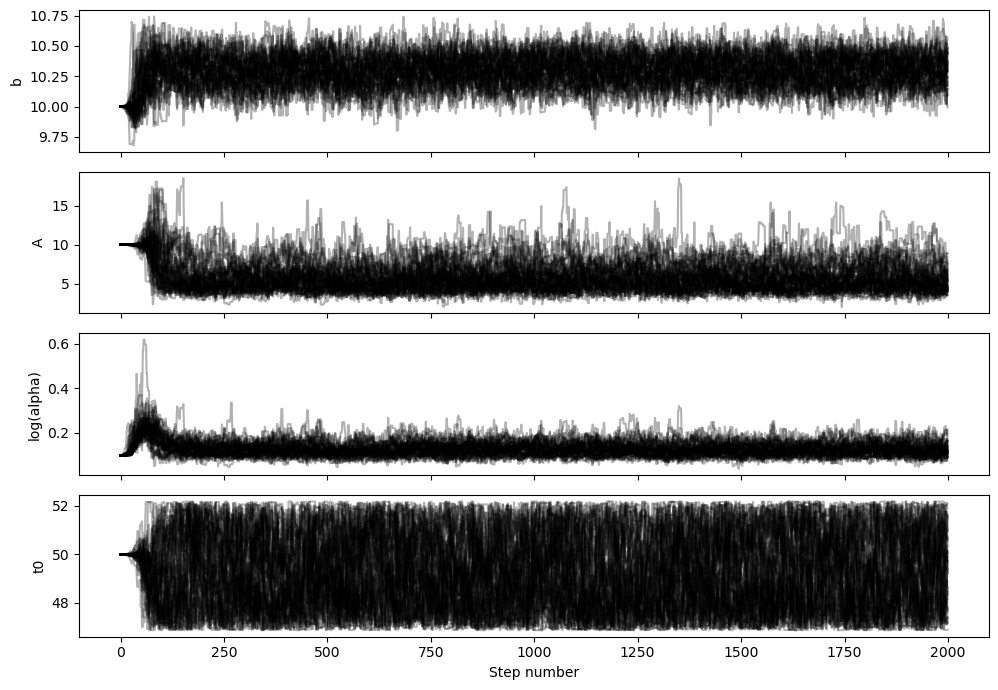

In [7]:
trial = 2000
try_sempler = emcee.EnsembleSampler(nwalkers, ndim, logPosterior, args=(time, flux, error))
initial_pos = np.array([10, 10, 0.1, 50]) + 1e-4 * np.random.randn(nwalkers, ndim)
try_sempler.run_mcmc(initial_pos, trial, progress=True)

traces = try_sempler.get_chain()
labels = ["b", "A", "log(alpha)", "t0"]
fig, axes = plt.subplots(ndim, figsize=(10, 7), sharex=True)
for i in range(ndim):
    ax = axes[i]
    ax.plot(traces[:, :, i], "k", alpha=0.3)
    ax.set_ylabel(labels[i])
axes[-1].set_xlabel("Step number")
plt.tight_layout()
plt.show()

Let's conclude that we need at least 100 steps to burn the chain.

In [8]:
tau = try_sempler.get_autocorr_time()
print(tau)
thin = int(np.max(tau) + 1)

AutocorrError: The chain is shorter than 50 times the integrated autocorrelation time for 4 parameter(s). Use this estimate with caution and run a longer chain!
N/50 = 40;
tau: [53.72734928 62.88925286 53.05366027 56.38797134]

In [9]:
# Run the sampler for a longer time to get better estimates, considering the autocorrelation time
burn = 500
nsteps = 10000

sempler = emcee.EnsembleSampler(nwalkers, ndim, logPosterior, args=(time, flux, error))

initial_pos = np.array([10, 10, 0.1, 50]) + 1e-4 * np.random.randn(nwalkers, ndim)

sempler.run_mcmc(initial_pos, nsteps, progress=True)

  0%|          | 0/10000 [00:00<?, ?it/s]/var/folders/y3/hmkzfhj13553n22ygq7syz5r0000gn/T/ipykernel_33408/3384519921.py:15: RuntimeWarning: invalid value encountered in log
  if 0 < b < 50 and 0 < A < 50 and -5 < np.log(alpha) < 5 and 0 < t0 < 100:
100%|██████████| 10000/10000 [00:11<00:00, 895.64it/s]


State([[10.33133747  9.03755845  0.14187824 48.12351633]
 [10.34383269  5.63695308  0.10672245 48.43925415]
 [10.21898006  5.72847937  0.11199275 48.9915411 ]
 [10.51931804  4.13777875  0.15687793 51.4272312 ]
 [10.20374507  3.60505008  0.07728723 51.72664943]
 [10.33298675  4.31850947  0.13351545 50.78219582]
 [10.22487538  6.05070257  0.09143943 47.06892891]
 [10.34126924  6.39628766  0.11756983 47.47927717]
 [10.25210585  4.89763334  0.11819699 49.59473247]
 [10.32981321  7.8862096   0.12539468 47.70127105]
 [10.35519229  4.26766907  0.15020869 51.05384208]
 [10.38659285  6.21631281  0.13766359 48.80759453]
 [10.28560845  4.48505433  0.09981238 49.29938995]
 [10.34276105  4.31417559  0.09521221 50.10943684]
 [10.23623441  4.27653565  0.08545091 48.35025185]
 [10.2897808   7.85221308  0.13481781 47.59054598]
 [10.21777114  5.33046374  0.08759371 47.98281884]
 [10.36944681  4.68922551  0.13121406 50.86712758]
 [10.0259186   7.10896289  0.13057472 47.45052324]
 [10.29569427  5.51180422

In [10]:
tau = sempler.get_autocorr_time()
print(tau)
thin = int(np.max(tau) + 1)

[53.41994852 77.85681431 62.31462622 69.22841696]


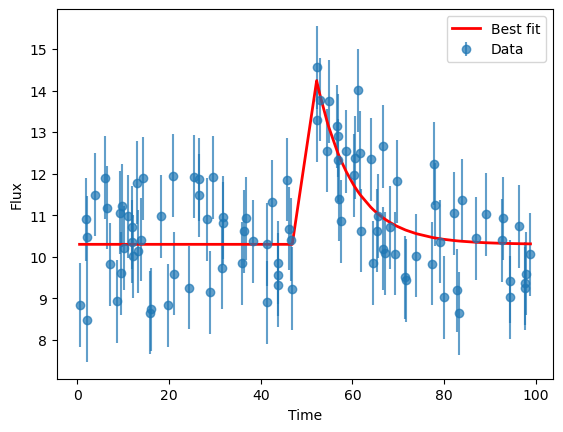

In [11]:
samples = sempler.get_chain(discard=burn, thin=thin, flat=True)

best_params = samples.mean(axis=0)

plt.errorbar(time, flux, yerr=error, fmt='o', label='Data', alpha=0.7)
model_flux = Model(time, *best_params)
plt.plot(time, model_flux, 'r-', label='Best fit', linewidth=2)
plt.xlabel('Time')
plt.ylabel('Flux')
plt.legend()
plt.show()

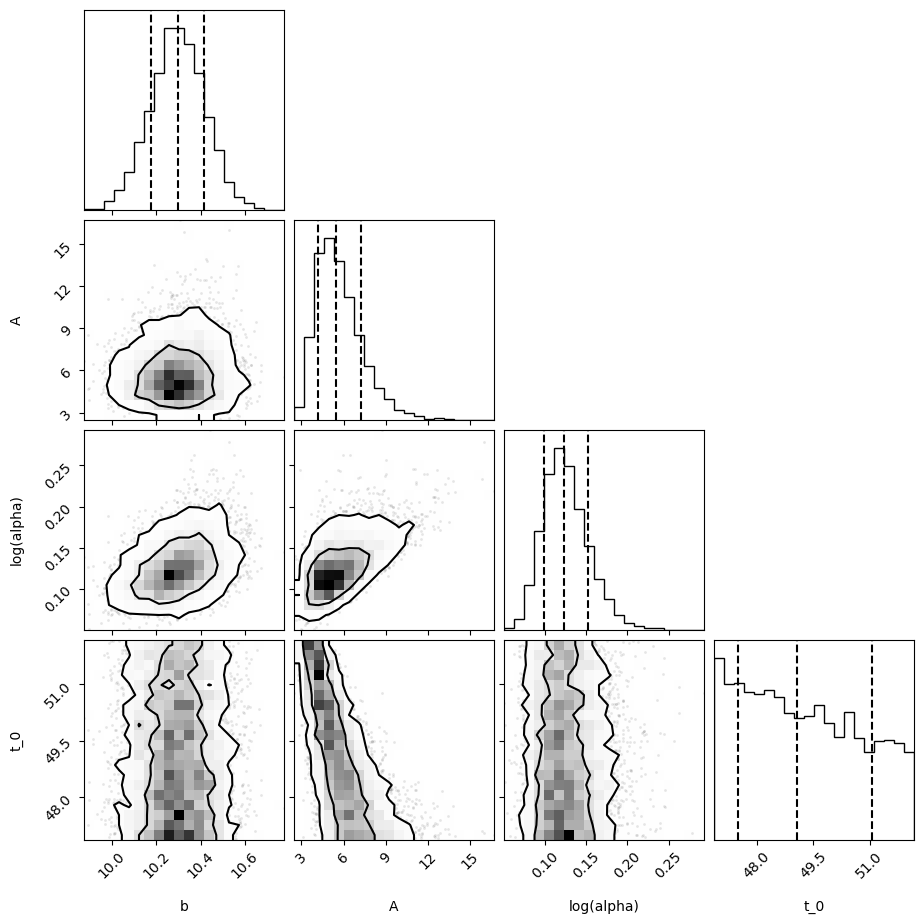

In [12]:
import corner as corner

labels = ["b", "A", "log(alpha)", "t_0"]

fig = corner.corner(
    samples, 
    labels=labels, 
    levels=[0.68, 0.95],
    quantiles=[0.16, 0.5, 0.84]
)
plt.show()

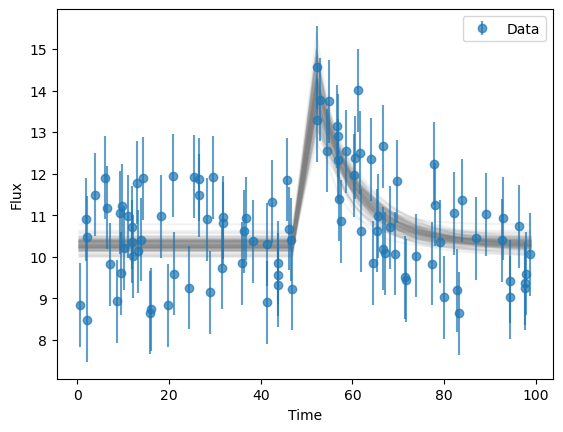

In [13]:
random_samples = samples[np.random.choice(samples.shape[0], size=100, replace=False)]

for i in range(len(random_samples)):
    y = Model(time, *random_samples[i])
    plt.plot(time, y, color='gray', alpha=0.1)
plt.errorbar(time, flux, yerr=error, fmt='o', label='Data', alpha=0.7)
plt.xlabel('Time')
plt.ylabel('Flux')
plt.legend()
plt.show()


In [14]:
median_params = np.median(samples, axis=0)
percentiles_params = np.percentile(samples, [5, 95], axis=0)

for i, param in enumerate(labels):
    print(f"{param}: {median_params[i]:.3f} (+{percentiles_params[1, i] - median_params[i]:.3f}, -{median_params[i] - percentiles_params[0, i]:.3f})")

b: 10.296 (+0.200, -0.201)
A: 5.432 (+3.417, -1.843)
log(alpha): 0.122 (+0.053, -0.037)
t_0: 49.079 (+2.731, -2.026)


We can also check the walker’s behavior.

Mean acceptance fraction: 0.533046
Acceptance fraction (per walker, first 10): [0.5355 0.5371 0.5266 0.5389 0.534  0.5326 0.5455 0.5255 0.5331 0.5327]


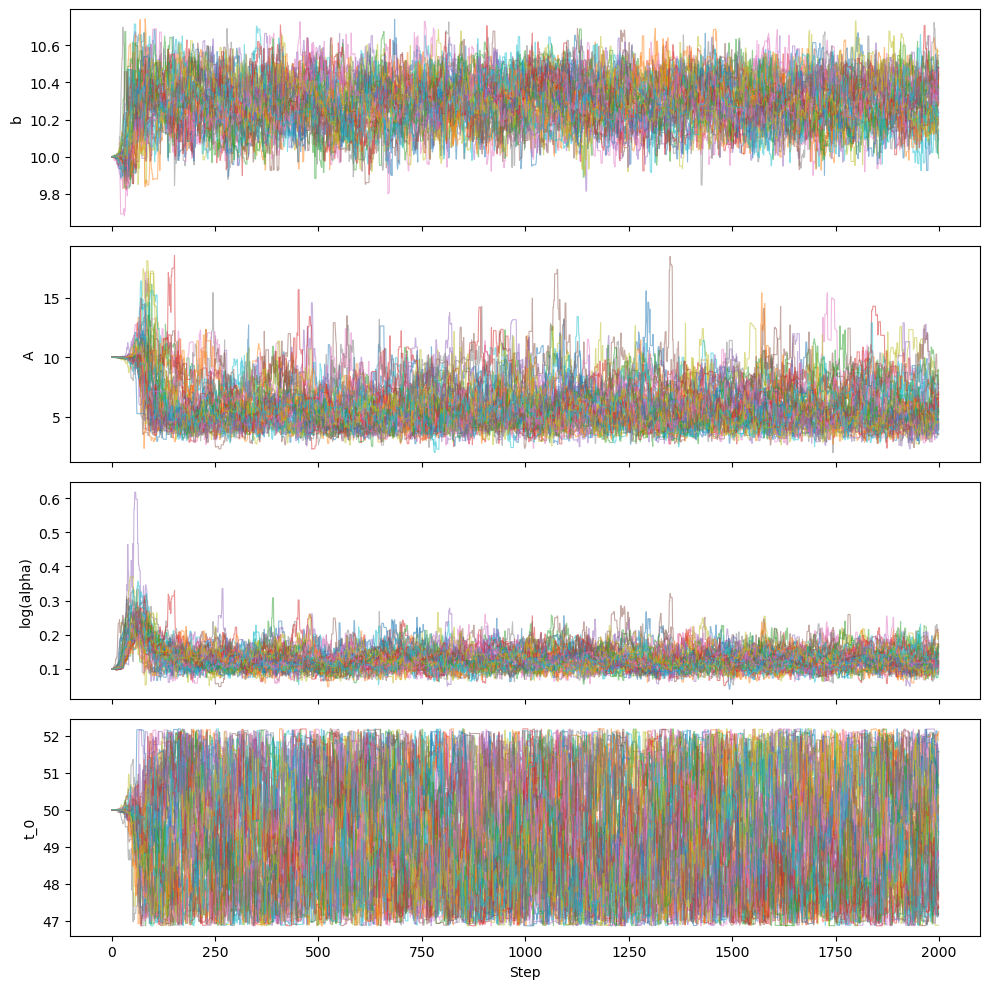

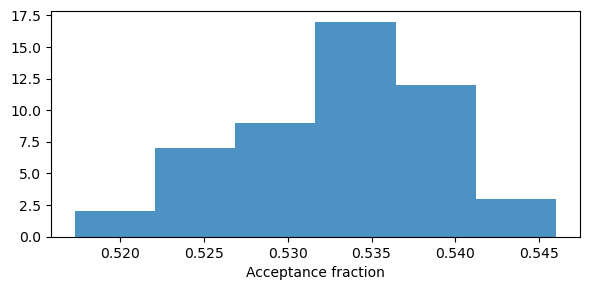

In [15]:
acc = getattr(sempler, "acceptance_fraction", None)
if acc is not None:
    print("Mean acceptance fraction:", acc.mean())
    print("Acceptance fraction (per walker, first 10):", acc[:10])

fig, axes = plt.subplots(ndim, 1, figsize=(10, 2.5 * ndim), sharex=True)
for j in range(ndim):
    ax = axes[j]
    ax.plot(traces[:, :, j], lw=0.8, alpha=0.5)
    ax.set_ylabel(labels[j])
axes[-1].set_xlabel("Step")
plt.tight_layout()
plt.show()

if acc is not None:
    plt.figure(figsize=(6,3))
    plt.hist(acc, bins='scott', alpha=0.8)
    plt.xlabel("Acceptance fraction")
    plt.tight_layout()
    plt.show()

### Savage-Dickey ratio

Use to check that indeed we have a signal over noise.

In [22]:
from sklearn.neighbors import KernelDensity
from sklearn.model_selection import GridSearchCV

def kde(samples, bandwith, kernel):
    kde = KernelDensity(bandwidth=bandwith, kernel=kernel)
    kde.fit(samples[:, None])
    return kde

In [23]:
gscv = GridSearchCV(KernelDensity(), {'bandwidth': np.logspace(-2, 2, 20)}, cv=5)
gscv.fit(samples[:, 1].reshape(-1, 1))
gscv.best_params_

{'bandwidth': 0.29763514416313175}

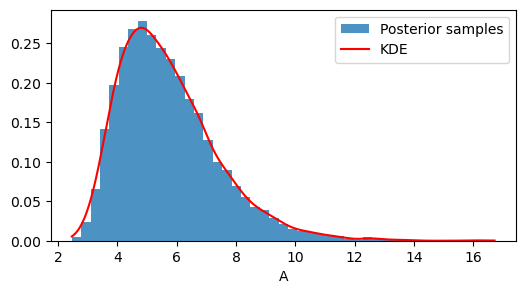

In [24]:
posterior_samples = samples[:, 1]
posterior_kde = kde(posterior_samples, bandwith=gscv.best_params_['bandwidth'], kernel='gaussian')

plt.figure(figsize=(6,3))
plt.hist(posterior_samples, bins='scott', density=True, alpha=0.8, label='Posterior samples')
x = np.linspace(posterior_samples.min(), posterior_samples.max(), 1000)[:, None]
log_dens = posterior_kde.score_samples(x)
plt.plot(x, np.exp(log_dens), 'r-', label='KDE')
plt.xlabel("A")
plt.legend()

In [25]:
A_ref = 0.0
posterior_density = np.exp(posterior_kde.score_samples([[A_ref]]))[0]
prior_density = 1 / 50
bayes_factor = prior_density / posterior_density

print(f'Posterior density at A={A_ref}: {posterior_density:.3e}')
print(f'Prior density at A={A_ref}: {prior_density:.3e}')
print(f'Savage-Dickey Bayes factor: {bayes_factor:.3f}')

Posterior density at A=0.0: 3.543e-19
Prior density at A=0.0: 2.000e-02
Savage-Dickey Bayes factor: 56443739656906200.000


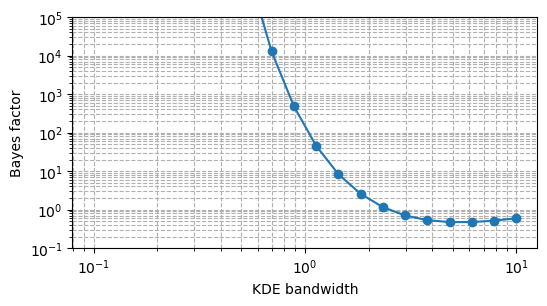

In [35]:
bandwith = np.logspace(-1, 1, 20)
bayesian_factors = []

for bw in bandwith:
    posterior_kde = kde(posterior_samples, bandwith=bw, kernel='gaussian')
    posterior_density = np.exp(posterior_kde.score_samples([[A_ref]]))[0]
    bayes_factor = prior_density / posterior_density
    bayesian_factors.append(bayes_factor)

plt.figure(figsize=(6,3))
plt.loglog(bandwith, bayesian_factors, marker='o')
plt.xlabel('KDE bandwidth')
plt.ylabel('Bayes factor')
plt.ylim(1e-1, 1e5)
plt.grid(True, which="both", ls="--")
plt.show()

We can confirm what we expected: we have identified a clear signal over noise. The last plot shows the importance of cross-validation for understanding the reliability of Bayes Factor, since it is sensitive to the KDE bandwidth choice in the tail region.